# Task A2: Predicting Concrete Compressive Strength

| Field | Details |
|-------|--------|
| **Student** | Muhammad Ahmad |
| **SAP ID** | 70177776 |
| **Section** | BSRAI-C |
| **Course** | AI-101 Introduction to Artificial Intelligence |
| **University** | The University of Lahore |

---

## Objective
Predict the **compressive strength (MPa)** of concrete from 8 mixture-design inputs using multiple regression models.  
We engineer domain features (water/cement ratio, log-age), compare five models, tune hyper-parameters with cross-validation, and analyse where and why errors occur.

**Dataset**: UCI Concrete Compressive Strength (ID 165) — 1 030 samples × 8 numeric features.

---
## 1. Setup & Imports

In [1]:
# ── Standard libraries ──────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings, os

# ── Scikit-learn ────────────────────────────────────────────────────
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ── UCI repository helper ──────────────────────────────────────────
from ucimlrepo import fetch_ucirepo

# ── Reproducibility & aesthetics ───────────────────────────────────
SEED = 42
np.random.seed(SEED)
warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams.update({'figure.dpi': 120, 'savefig.dpi': 150,
                     'figure.figsize': (10, 6), 'font.size': 11})

# ── Output directories ─────────────────────────────────────────────
FIG_DIR = r'C:\Users\muham\.gemini\antigravity\scratch\AI101-ML-Assignment-70177776\A2_Concrete_Strength\figures'
os.makedirs(FIG_DIR, exist_ok=True)

print('All imports successful. ✔')

All imports successful. ✔


---
## 2. Load the Dataset

In [2]:
# Fetch from UCI repository
concrete = fetch_ucirepo(id=165)

X_raw = concrete.data.features.copy()
y = concrete.data.targets.iloc[:, 0].copy()  # flatten to Series

# Clean column names for convenience
X_raw.columns = ['Cement', 'BlastFurnaceSlag', 'FlyAsh', 'Water',
                  'Superplasticizer', 'CoarseAggregate', 'FineAggregate', 'Age']
y.name = 'Strength'

print(f'Features shape : {X_raw.shape}')
print(f'Target shape   : {y.shape}')
print(f'Target range   : {y.min():.2f} – {y.max():.2f} MPa')

Features shape : (1030, 8)
Target shape   : (1030,)
Target range   : 2.33 – 82.60 MPa


In [3]:
# Quick sanity check
df = X_raw.copy()
df['Strength'] = y
df.head(10)

,Cement,BlastFurnaceSlag,FlyAsh,Water,Superplasticizer,CoarseAggregate,FineAggregate,Age,Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30
5,266.0,114.0,0.0,228.0,0.0,932.0,670.0,90,47.03
6,380.0,95.0,0.0,228.0,0.0,932.0,594.0,365,43.70
7,380.0,95.0,0.0,228.0,0.0,932.0,594.0,28,36.45
8,266.0,114.0,0.0,228.0,0.0,932.0,670.0,28,45.85
9,475.0,0.0,0.0,228.0,0.0,932.0,594.0,28,39.29


In [4]:
# Data types and missing values
print('Missing values per column:')
print(df.isnull().sum())
print()
df.describe().round(2)

Missing values per column:
Cement              0
BlastFurnaceSlag    0
FlyAsh              0
Water               0
Superplasticizer    0
CoarseAggregate     0
FineAggregate       0
Age                 0
Strength            0
dtype: int64



,Cement,BlastFurnaceSlag,FlyAsh,Water,Superplasticizer,CoarseAggregate,FineAggregate,Age,Strength
count,1030.00,1030.00,1030.00,1030.00,1030.00,1030.00,1030.00,1030.00,1030.00
mean,281.17,73.90,54.19,181.57,6.20,972.92,773.58,45.66,35.82
std,104.51,86.28,64.00,21.35,5.97,77.75,80.18,63.17,16.71
min,102.00,0.00,0.00,121.80,0.00,801.00,594.00,1.00,2.33
25%,192.38,0.00,0.00,164.90,0.00,932.00,730.95,7.00,23.71
50%,272.90,22.00,0.00,185.00,6.40,968.00,779.50,28.00,34.44
75%,350.00,142.95,118.30,192.00,10.20,1029.40,824.00,56.00,46.14
max,540.00,359.40,200.10,247.00,32.20,1145.00,992.60,365.00,82.60


---
## 3. Exploratory Data Analysis (EDA)

### 3.1 Feature Histograms


⚠ Note: Age is heavily RIGHT-SKEWED — most samples are ≤ 28 days, with a long tail out to 365 days.


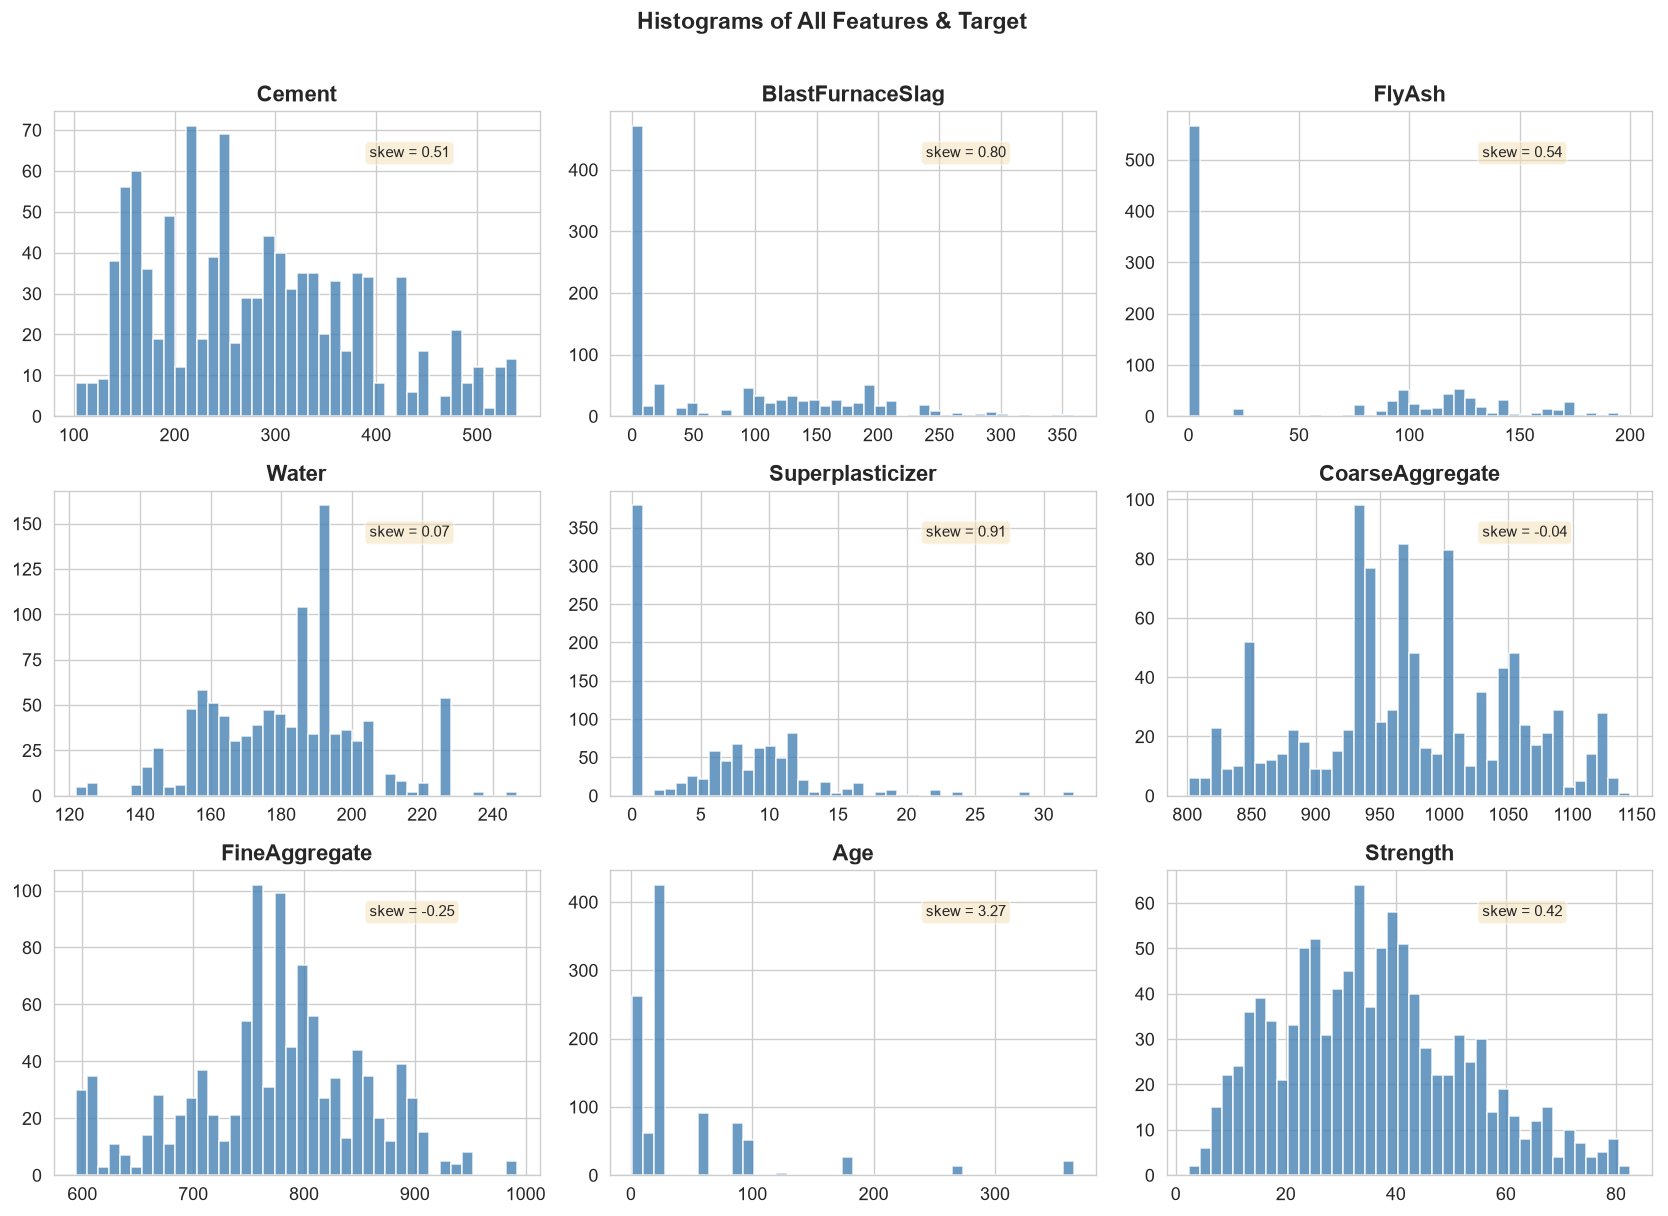

In [5]:
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, col in zip(axes.ravel(), df.columns):
    ax.hist(df[col], bins=40, edgecolor='white', alpha=0.8, color='steelblue')
    ax.set_title(col, fontweight='bold')
    skew_val = df[col].skew()
    ax.annotate(f'skew = {skew_val:.2f}', xy=(0.65, 0.85),
                xycoords='axes fraction', fontsize=9,
                bbox=dict(boxstyle='round', fc='wheat', alpha=0.5))
plt.suptitle('Histograms of All Features & Target', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'histograms.png'), bbox_inches='tight')
plt.show()
print('\n⚠ Note: Age is heavily RIGHT-SKEWED — most samples are ≤ 28 days, '
      'with a long tail out to 365 days.')

### 3.2 Correlation Matrix


Correlation of each feature with Strength:
Cement              0.497832
Superplasticizer    0.366079
Age                 0.328873
BlastFurnaceSlag    0.134829
FlyAsh             -0.105755
CoarseAggregate    -0.164935
FineAggregate      -0.167241
Water              -0.289633


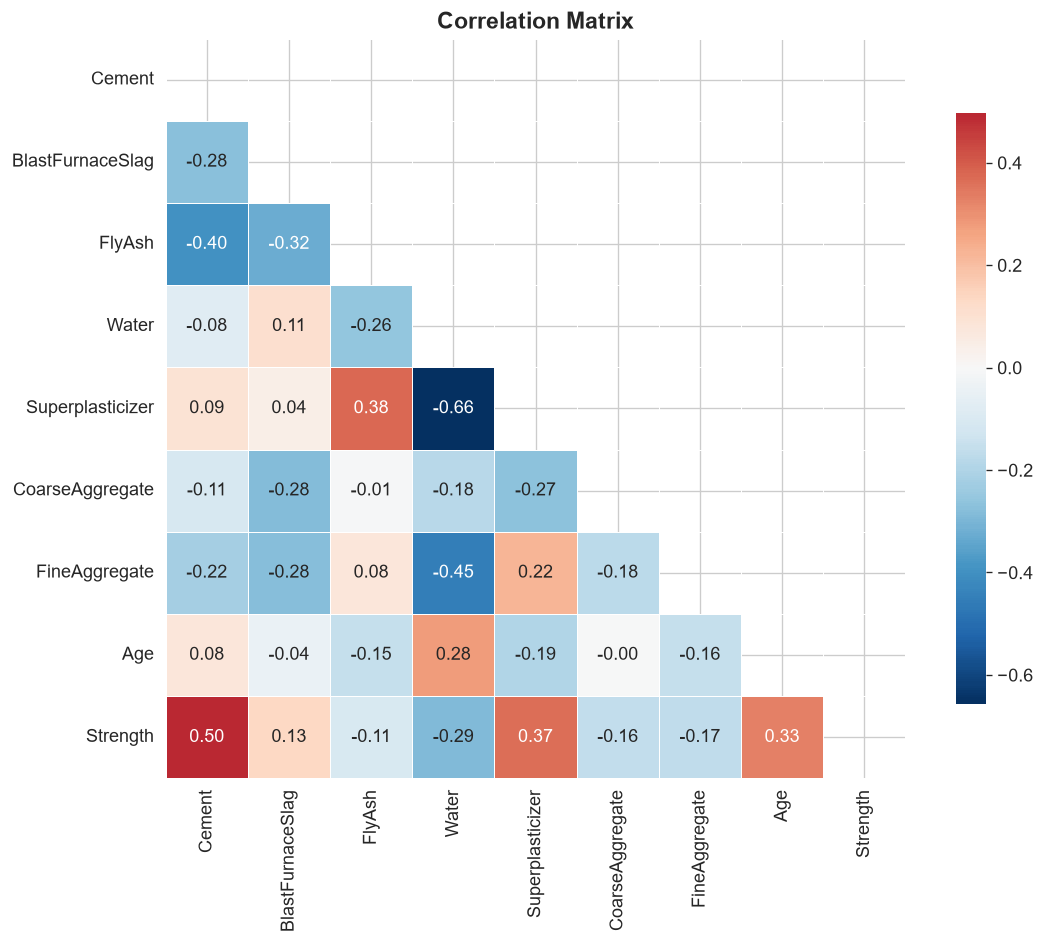

In [6]:
corr = df.corr()

fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, linewidths=0.5, ax=ax, square=True,
            cbar_kws={'shrink': 0.8})
ax.set_title('Correlation Matrix', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'correlation_matrix.png'), bbox_inches='tight')
plt.show()

print('\nCorrelation of each feature with Strength:')
print(corr['Strength'].drop('Strength').sort_values(ascending=False).to_string())

### 3.3 Scatter Plots: Strength vs Age & Water/Cement Ratio

Both relationships are clearly NON-LINEAR:
  • Strength increases with age but with diminishing returns (logarithmic trend).
  • Higher water/cement ratio → lower strength (inverse relationship – Abram's Law).


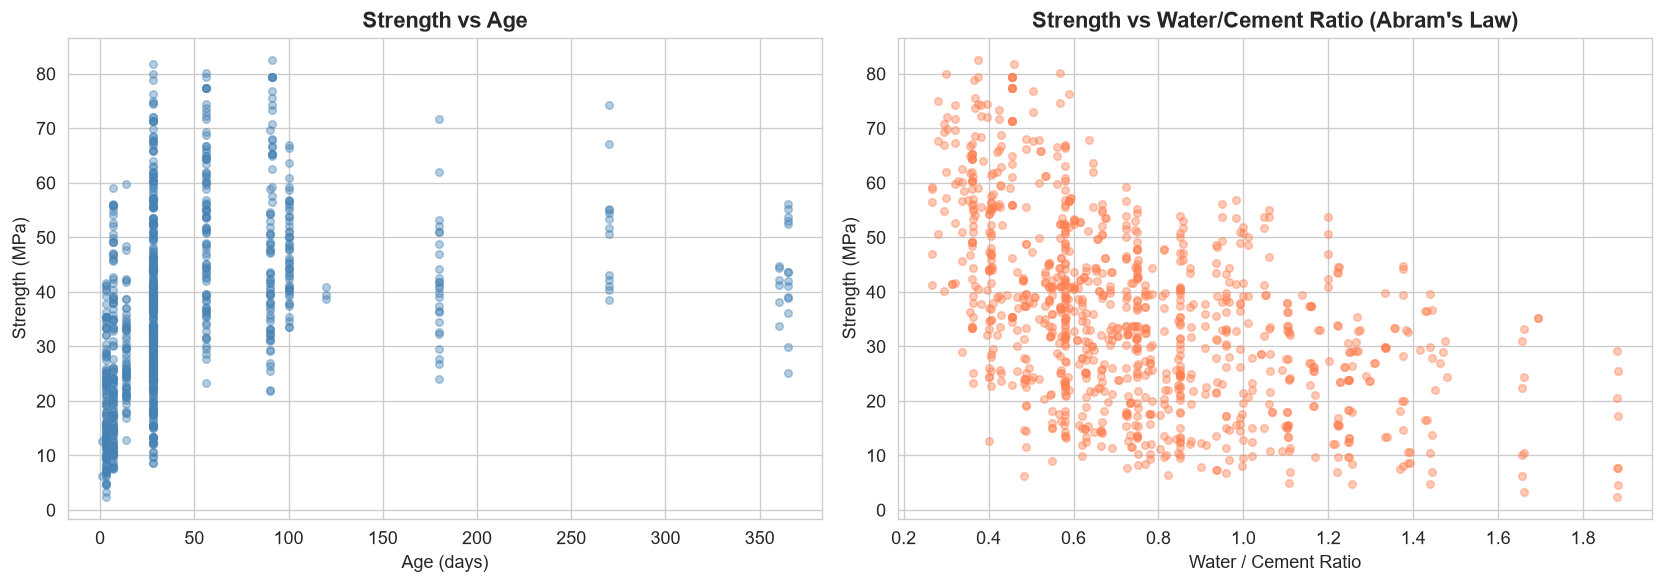

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ── Strength vs Age ─────────────────────────────────────────────────
axes[0].scatter(df['Age'], df['Strength'], alpha=0.4, s=20, c='steelblue')
axes[0].set_xlabel('Age (days)')
axes[0].set_ylabel('Strength (MPa)')
axes[0].set_title('Strength vs Age', fontweight='bold')

# ── Strength vs Water/Cement ratio ──────────────────────────────────
wc_ratio = df['Water'] / df['Cement']
axes[1].scatter(wc_ratio, df['Strength'], alpha=0.4, s=20, c='coral')
axes[1].set_xlabel('Water / Cement Ratio')
axes[1].set_ylabel('Strength (MPa)')
axes[1].set_title('Strength vs Water/Cement Ratio (Abram\'s Law)', fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'scatter_age_wc.png'), bbox_inches='tight')
plt.show()

print('Both relationships are clearly NON-LINEAR:')
print('  • Strength increases with age but with diminishing returns (logarithmic trend).')
print('  • Higher water/cement ratio → lower strength (inverse relationship – Abram\'s Law).')

### 3.4 Pairplot of Top Features

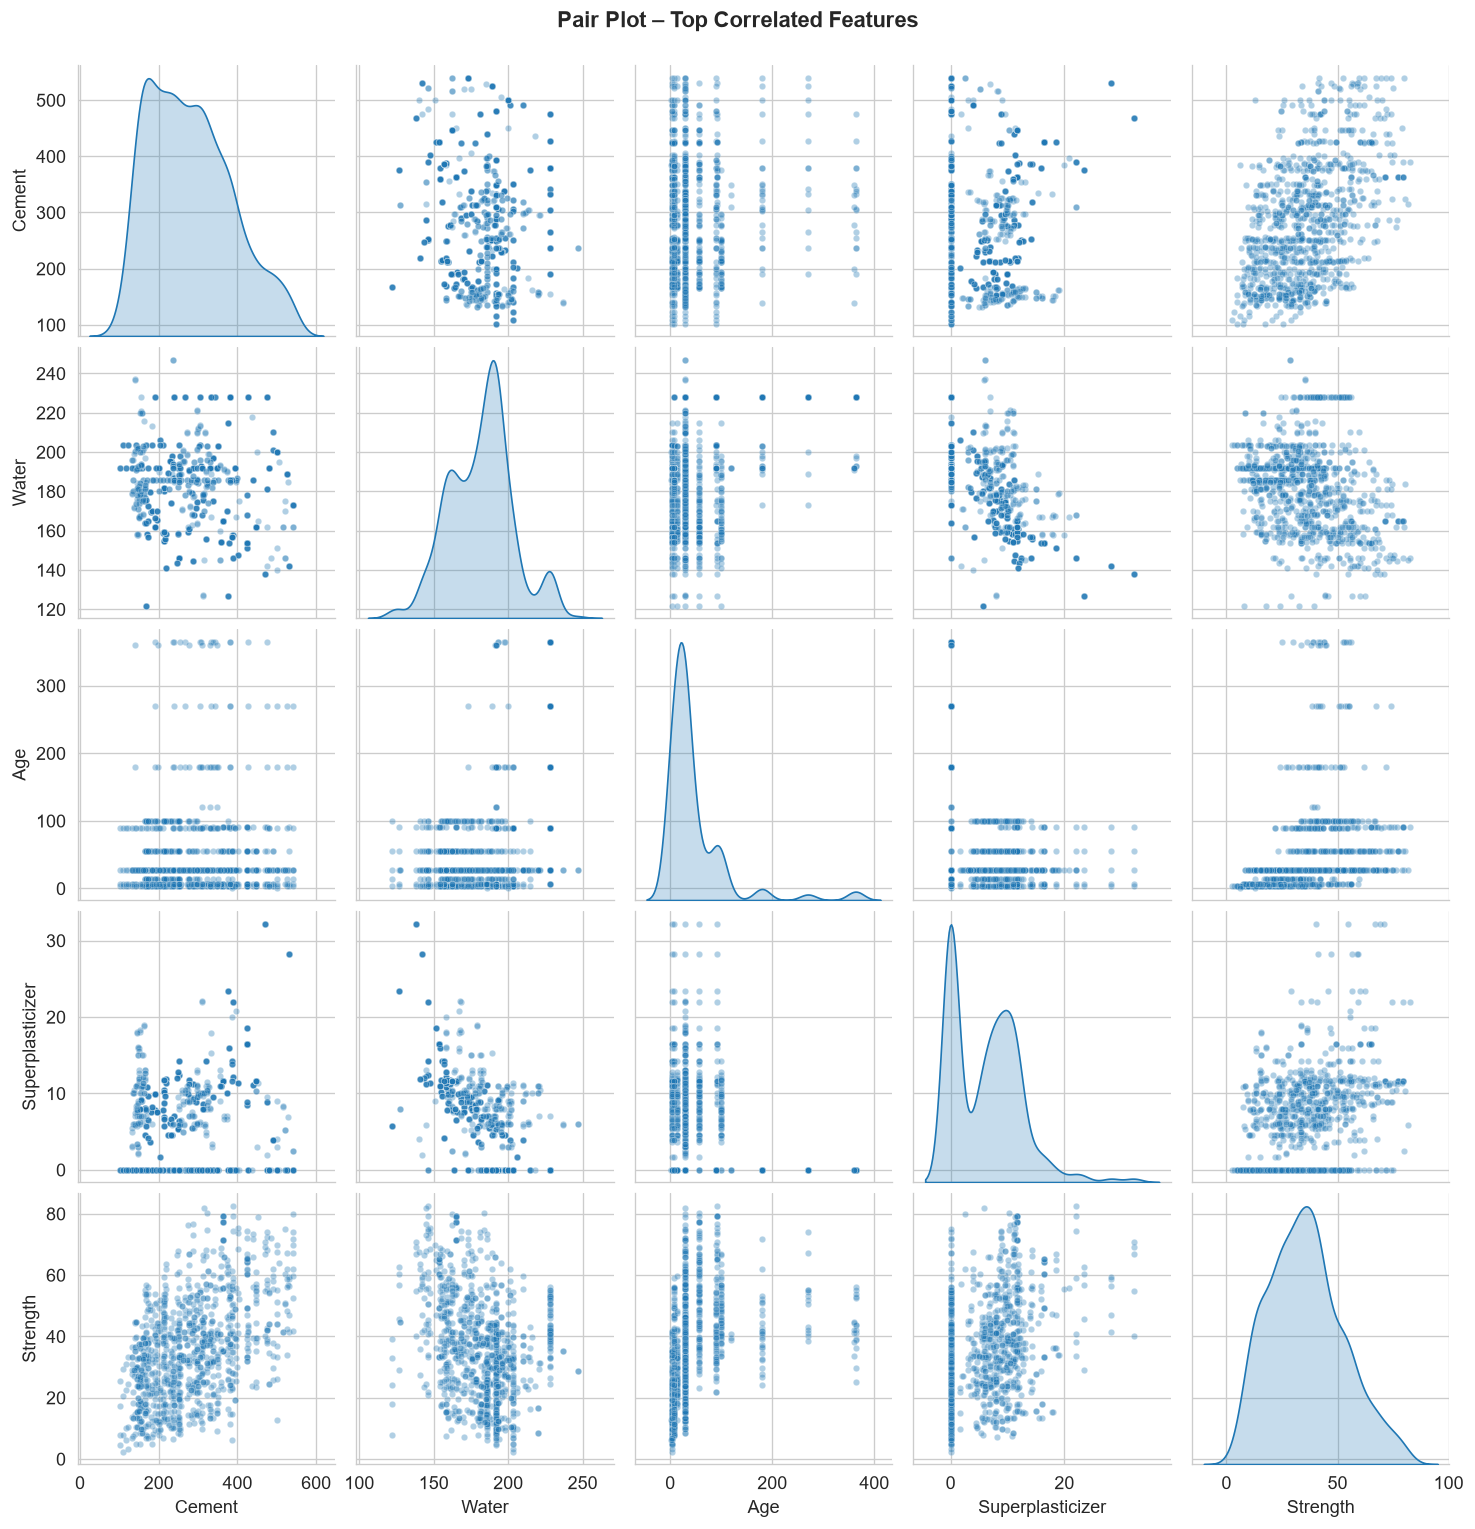

In [8]:
top_feats = ['Cement', 'Water', 'Age', 'Superplasticizer', 'Strength']
g = sns.pairplot(df[top_feats], diag_kind='kde', plot_kws={'alpha': 0.35, 's': 15})
g.fig.suptitle('Pair Plot – Top Correlated Features', y=1.02, fontweight='bold')
plt.savefig(os.path.join(FIG_DIR, 'pairplot_top.png'), bbox_inches='tight')
plt.show()

---
## 4. Feature Engineering

In [9]:
def add_engineered_features(X):
    """Add water/cement ratio and log(Age) to feature matrix."""
    Xe = X.copy()
    Xe['WaterCementRatio'] = Xe['Water'] / Xe['Cement']
    Xe['LogAge'] = np.log1p(Xe['Age'])  # log(1+Age) handles Age=0 safely
    return Xe

X_eng = add_engineered_features(X_raw)

print('Original features  :', list(X_raw.columns))
print('Engineered features:', list(X_eng.columns))
print(f'Shape: {X_raw.shape} → {X_eng.shape}')
X_eng.head()

Original features  : ['Cement', 'BlastFurnaceSlag', 'FlyAsh', 'Water', 'Superplasticizer', 'CoarseAggregate', 'FineAggregate', 'Age']
Engineered features: ['Cement', 'BlastFurnaceSlag', 'FlyAsh', 'Water', 'Superplasticizer', 'CoarseAggregate', 'FineAggregate', 'Age', 'WaterCementRatio', 'LogAge']
Shape: (1030, 8) → (1030, 10)


,Cement,BlastFurnaceSlag,FlyAsh,Water,Superplasticizer,CoarseAggregate,FineAggregate,Age,WaterCementRatio,LogAge
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,0.300000,3.367296
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,0.300000,3.367296
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,0.685714,5.602119
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,0.685714,5.902633
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,0.966767,5.888878


---
## 5. Train / Test Split

In [10]:
# Split WITHOUT engineered features
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.20, random_state=SEED)

# Split WITH engineered features (same indices)
X_train_eng = add_engineered_features(X_train_raw)
X_test_eng  = add_engineered_features(X_test_raw)

print(f'Train: {X_train_raw.shape[0]} samples')
print(f'Test : {X_test_raw.shape[0]} samples')

Train: 824 samples
Test : 206 samples


---
## 6. Helper Functions

In [11]:
def evaluate_model(name, model, X_tr, X_te, y_tr, y_te, cv_folds=5):
    """Fit, predict, compute CV & test metrics, return dict of results."""
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)

    mae  = mean_absolute_error(y_te, y_pred)
    rmse = np.sqrt(mean_squared_error(y_te, y_pred))
    r2   = r2_score(y_te, y_pred)

    # 5-fold CV on training set (negative MSE → RMSE)
    cv_scores = cross_val_score(model, X_tr, y_tr, cv=cv_folds,
                                scoring='neg_mean_squared_error')
    cv_rmse = np.sqrt(-cv_scores)

    result = {
        'Model': name,
        'MAE': mae,
        'RMSE': rmse,
        'R²': r2,
        'CV RMSE Mean': cv_rmse.mean(),
        'CV RMSE Std': cv_rmse.std(),
        'y_pred': y_pred
    }

    print(f'{name:40s}  MAE={mae:6.2f}  RMSE={rmse:6.2f}  R²={r2:.4f}  '
          f'CV-RMSE={cv_rmse.mean():.2f}±{cv_rmse.std():.2f}')
    return result


def plot_pred_vs_actual(y_true, y_pred, title, filepath):
    """Predicted vs actual scatter + 45° line."""
    fig, ax = plt.subplots(figsize=(7, 6))
    ax.scatter(y_true, y_pred, alpha=0.45, s=20, c='steelblue', edgecolors='k', linewidths=0.3)
    lims = [min(y_true.min(), y_pred.min()) - 3, max(y_true.max(), y_pred.max()) + 3]
    ax.plot(lims, lims, 'r--', lw=1.5, label='Perfect prediction')
    ax.set_xlabel('Actual Strength (MPa)')
    ax.set_ylabel('Predicted Strength (MPa)')
    ax.set_title(title, fontweight='bold')
    ax.legend()
    ax.set_xlim(lims); ax.set_ylim(lims)
    plt.tight_layout()
    plt.savefig(filepath, bbox_inches='tight')
    plt.show()


def plot_residuals(y_true, y_pred, title, filepath):
    """Residual plot (residuals vs predicted)."""
    residuals = y_true - y_pred
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.scatter(y_pred, residuals, alpha=0.45, s=20, c='coral', edgecolors='k', linewidths=0.3)
    ax.axhline(0, color='black', lw=1, ls='--')
    ax.set_xlabel('Predicted Strength (MPa)')
    ax.set_ylabel('Residual (Actual − Predicted)')
    ax.set_title(title, fontweight='bold')
    plt.tight_layout()
    plt.savefig(filepath, bbox_inches='tight')
    plt.show()

Evaluation helper function evaluate_model() compiled successfully.


---
## 7. Model Training & Evaluation

We train five models on the **engineered** feature set, then compare.

### 7.1 Model 1 — Linear Regression (Baseline)

In [12]:
lr_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('lr', LinearRegression())
])

results = []
res = evaluate_model('Linear Regression', lr_pipe,
                     X_train_eng, X_test_eng, y_train, y_test)
results.append(res)

Linear Regression                         MAE=  5.29  RMSE=  6.57  R²=0.8323  CV-RMSE=7.09±0.48


### 7.2 Model 2 — Polynomial + Ridge Regression (Tuned)

In [13]:
# ── Grid search over polynomial degree and Ridge alpha ─────────────
poly_ridge_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('poly', PolynomialFeatures(include_bias=False)),
    ('ridge', Ridge())
])

param_grid_pr = {
    'poly__degree': [2, 3],
    'ridge__alpha': [0.01, 0.1, 1.0, 10.0, 100.0]
}

gs_pr = GridSearchCV(poly_ridge_pipe, param_grid_pr, cv=5,
                     scoring='neg_mean_squared_error', n_jobs=-1)
gs_pr.fit(X_train_eng, y_train)

print(f'Best params: {gs_pr.best_params_}')
print(f'Best CV RMSE: {np.sqrt(-gs_pr.best_score_):.2f}')

res = evaluate_model('Poly + Ridge (tuned)', gs_pr.best_estimator_,
                     X_train_eng, X_test_eng, y_train, y_test)
results.append(res)

Best params: {'poly__degree': 3, 'ridge__alpha': 10.0}
Best CV RMSE: 5.05
Poly + Ridge (tuned)                      MAE=  4.07  RMSE=  5.76  R²=0.8712  CV-RMSE=5.03±0.43


### 7.3 Model 3 — Random Forest (Tuned)

In [14]:
rf_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('rf', RandomForestRegressor(random_state=SEED, n_jobs=-1))
])

param_grid_rf = {
    'rf__n_estimators': [200, 400],
    'rf__max_depth': [10, 20, None],
    'rf__min_samples_split': [2, 5]
}

gs_rf = GridSearchCV(rf_pipe, param_grid_rf, cv=5,
                     scoring='neg_mean_squared_error', n_jobs=-1)
gs_rf.fit(X_train_eng, y_train)

print(f'Best params: {gs_rf.best_params_}')
print(f'Best CV RMSE: {np.sqrt(-gs_rf.best_score_):.2f}')

res = evaluate_model('Random Forest (tuned)', gs_rf.best_estimator_,
                     X_train_eng, X_test_eng, y_train, y_test)
results.append(res)

Best params: {'rf__max_depth': 20, 'rf__min_samples_split': 2, 'rf__n_estimators': 400}
Best CV RMSE: 5.13
Random Forest (tuned)                     MAE=  3.70  RMSE=  5.38  R²=0.8878  CV-RMSE=5.11±0.39


### 7.4 Model 4 — Gradient Boosting (Tuned)

In [15]:
gb_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('gb', GradientBoostingRegressor(random_state=SEED))
])

param_grid_gb = {
    'gb__n_estimators': [200, 400],
    'gb__max_depth': [3, 5, 7],
    'gb__learning_rate': [0.05, 0.1]
}

gs_gb = GridSearchCV(gb_pipe, param_grid_gb, cv=5,
                     scoring='neg_mean_squared_error', n_jobs=-1)
gs_gb.fit(X_train_eng, y_train)

print(f'Best params: {gs_gb.best_params_}')
print(f'Best CV RMSE: {np.sqrt(-gs_gb.best_score_):.2f}')

res = evaluate_model('Gradient Boosting (tuned)', gs_gb.best_estimator_,
                     X_train_eng, X_test_eng, y_train, y_test)
results.append(res)

Best params: {'gb__learning_rate': 0.1, 'gb__max_depth': 3, 'gb__n_estimators': 400}
Best CV RMSE: 4.66
Gradient Boosting (tuned)                 MAE=  2.93  RMSE=  4.27  R²=0.9292  CV-RMSE=4.64±0.50


### 7.5 Model 5 — MLPRegressor (Neural Network)

In [16]:
mlp_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('mlp', MLPRegressor(random_state=SEED, max_iter=1000, early_stopping=True,
                         validation_fraction=0.1))
])

param_grid_mlp = {
    'mlp__hidden_layer_sizes': [(128, 64), (256, 128, 64)],
    'mlp__alpha': [0.0001, 0.001, 0.01],
    'mlp__learning_rate_init': [0.001, 0.01]
}

gs_mlp = GridSearchCV(mlp_pipe, param_grid_mlp, cv=5,
                      scoring='neg_mean_squared_error', n_jobs=-1)
gs_mlp.fit(X_train_eng, y_train)

print(f'Best params: {gs_mlp.best_params_}')
print(f'Best CV RMSE: {np.sqrt(-gs_mlp.best_score_):.2f}')

res = evaluate_model('MLPRegressor (tuned)', gs_mlp.best_estimator_,
                     X_train_eng, X_test_eng, y_train, y_test)
results.append(res)

Best params: {'mlp__alpha': 0.0001, 'mlp__hidden_layer_sizes': (256, 128, 64), 'mlp__learning_rate_init': 0.01}
Best CV RMSE: 5.17
MLPRegressor (tuned)                      MAE=  3.90  RMSE=  5.17  R²=0.8964  CV-RMSE=5.14±0.53


---
## 8. Results Summary Table

In [17]:
summary = pd.DataFrame([{
    'Model': r['Model'],
    'MAE': round(r['MAE'], 3),
    'RMSE': round(r['RMSE'], 3),
    'R²': round(r['R²'], 4),
    'CV RMSE (mean±std)': f"{r['CV RMSE Mean']:.2f} ± {r['CV RMSE Std']:.2f}"
} for r in results])

print('=' * 85)
print('                  MODEL COMPARISON — TEST SET RESULTS')
print('=' * 85)
print(summary.to_string(index=False))
print('=' * 85)

                  MODEL COMPARISON — TEST SET RESULTS
                    Model   MAE  RMSE     R² CV RMSE (mean±std)
        Linear Regression 5.289 6.573 0.8323        7.09 ± 0.48
     Poly + Ridge (tuned) 4.066 5.762 0.8712        5.03 ± 0.43
    Random Forest (tuned) 3.704 5.377 0.8878        5.11 ± 0.39
Gradient Boosting (tuned) 2.932 4.270 0.9292        4.64 ± 0.50
     MLPRegressor (tuned) 3.901 5.167 0.8964        5.14 ± 0.53


### 8.1 Bar Chart — Test RMSE Comparison

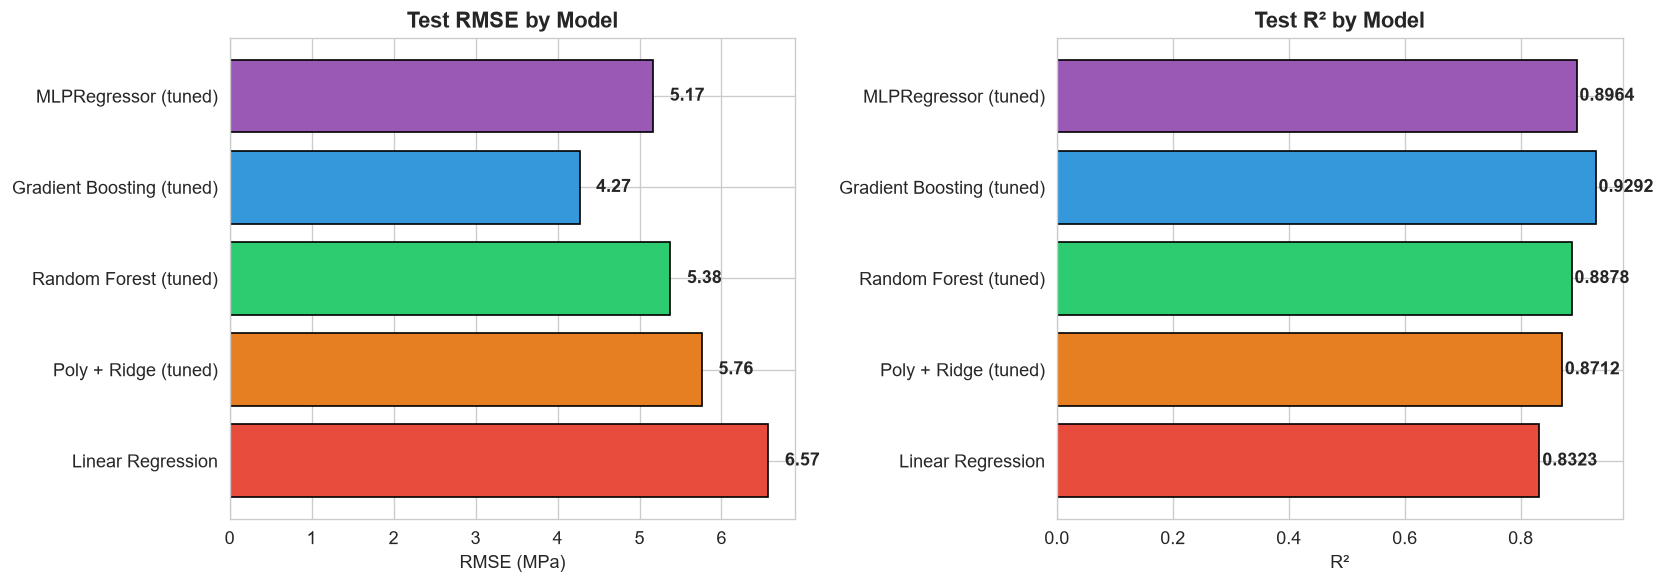

In [18]:
model_names = [r['Model'] for r in results]
rmse_vals   = [r['RMSE'] for r in results]
r2_vals     = [r['R²'] for r in results]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

colors = ['#e74c3c', '#e67e22', '#2ecc71', '#3498db', '#9b59b6']

axes[0].barh(model_names, rmse_vals, color=colors, edgecolor='black')
axes[0].set_xlabel('RMSE (MPa)')
axes[0].set_title('Test RMSE by Model', fontweight='bold')
for i, v in enumerate(rmse_vals):
    axes[0].text(v + 0.2, i, f'{v:.2f}', va='center', fontweight='bold')

axes[1].barh(model_names, r2_vals, color=colors, edgecolor='black')
axes[1].set_xlabel('R²')
axes[1].set_title('Test R² by Model', fontweight='bold')
for i, v in enumerate(r2_vals):
    axes[1].text(v + 0.005, i, f'{v:.4f}', va='center', fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'model_comparison.png'), bbox_inches='tight')
plt.show()

---
## 9. Best Model — Diagnostic Plots

Best model: Gradient Boosting (tuned)  (RMSE = 4.27)


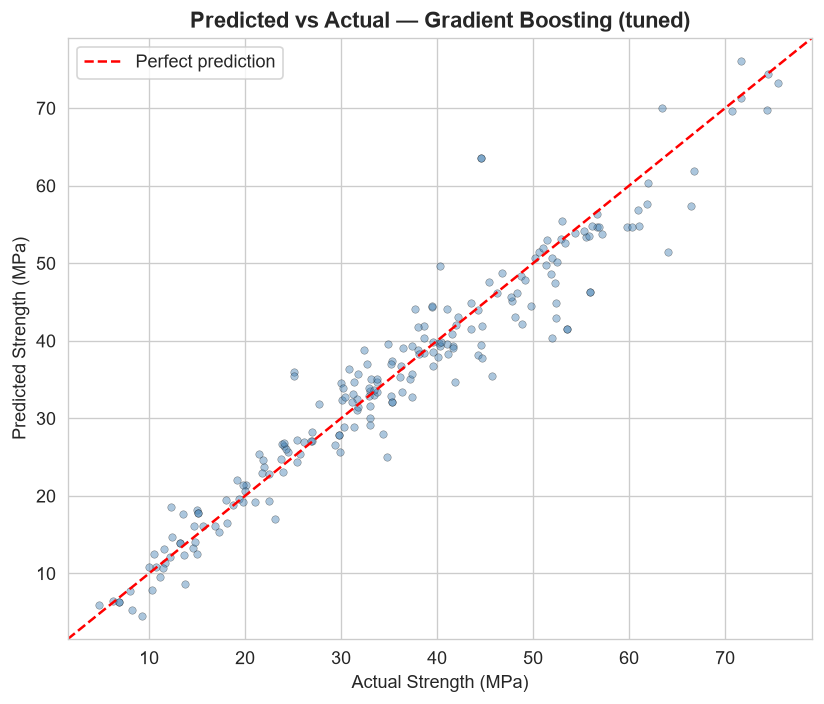

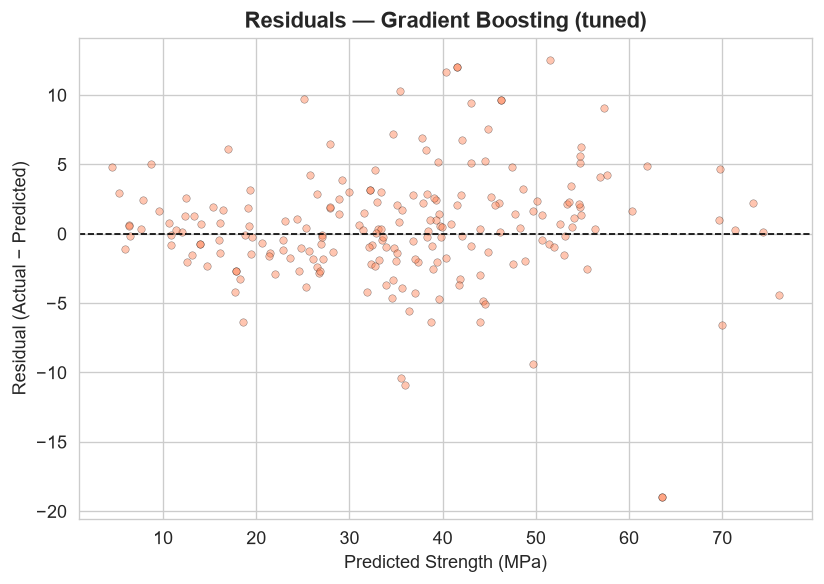

In [19]:
# Identify the best model by lowest test RMSE
best = min(results, key=lambda r: r['RMSE'])
print(f'Best model: {best["Model"]}  (RMSE = {best["RMSE"]:.2f})')

# Predicted vs Actual
plot_pred_vs_actual(y_test.values, best['y_pred'],
                    f'Predicted vs Actual — {best["Model"]}',
                    os.path.join(FIG_DIR, 'pred_vs_actual_best.png'))

# Residual plot
plot_residuals(y_test.values, best['y_pred'],
               f'Residuals — {best["Model"]}',
               os.path.join(FIG_DIR, 'residuals_best.png'))

### 9.1 Predicted-vs-Actual & Residuals for ALL Models

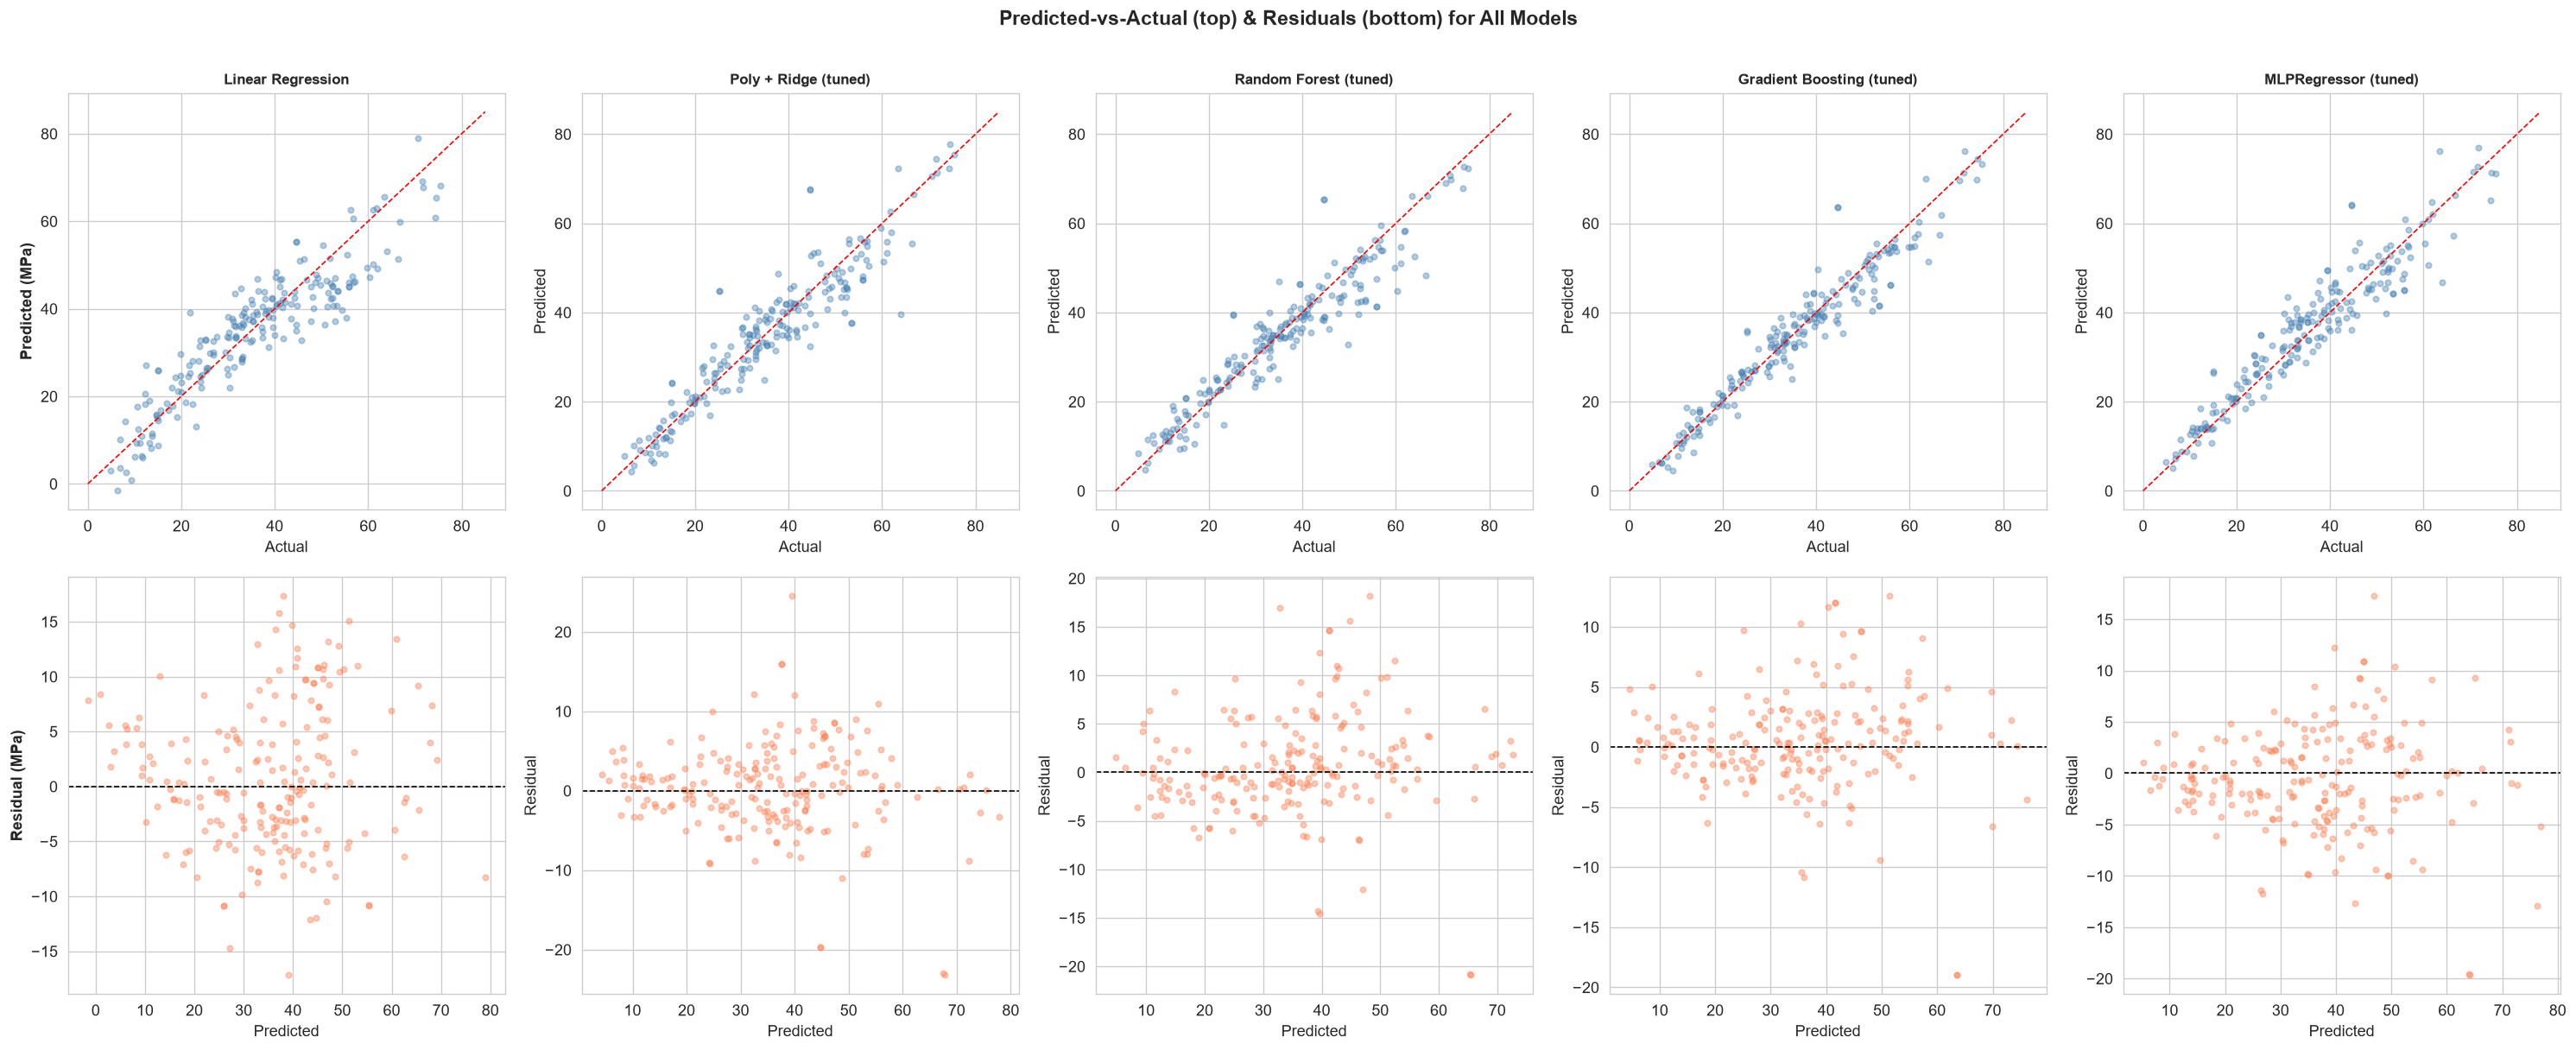

In [20]:
fig, axes = plt.subplots(2, len(results), figsize=(5 * len(results), 10))

for i, r in enumerate(results):
    # Row 0: pred vs actual
    ax = axes[0, i]
    ax.scatter(y_test, r['y_pred'], alpha=0.4, s=15, c='steelblue')
    lims = [0, 85]
    ax.plot(lims, lims, 'r--', lw=1)
    ax.set_title(r['Model'], fontsize=10, fontweight='bold')
    ax.set_xlabel('Actual'); ax.set_ylabel('Predicted')

    # Row 1: residuals
    ax = axes[1, i]
    residuals = y_test.values - r['y_pred']
    ax.scatter(r['y_pred'], residuals, alpha=0.4, s=15, c='coral')
    ax.axhline(0, color='k', ls='--', lw=1)
    ax.set_xlabel('Predicted'); ax.set_ylabel('Residual')

axes[0, 0].set_ylabel('Predicted (MPa)', fontweight='bold')
axes[1, 0].set_ylabel('Residual (MPa)', fontweight='bold')
fig.suptitle('Predicted-vs-Actual (top) & Residuals (bottom) for All Models',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'all_models_diagnostics.png'), bbox_inches='tight')
plt.show()

---
## 10. Feature Engineering Impact — With vs Without Engineered Features

In [21]:
# Compare all 5 models WITH and WITHOUT engineered features
models_to_compare = {
    'Linear Regression': Pipeline([('scaler', StandardScaler()), ('lr', LinearRegression())]),
    'Poly+Ridge (deg=2)': Pipeline([('scaler', StandardScaler()),
                                     ('poly', PolynomialFeatures(degree=2, include_bias=False)),
                                     ('ridge', Ridge(alpha=1.0))]),
    'Random Forest':  Pipeline([('scaler', StandardScaler()),
                                ('rf', RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1))]),
    'Gradient Boosting': Pipeline([('scaler', StandardScaler()),
                                   ('gb', GradientBoostingRegressor(n_estimators=300, random_state=SEED))]),
    'MLPRegressor': Pipeline([('scaler', StandardScaler()),
                              ('mlp', MLPRegressor(hidden_layer_sizes=(128, 64), max_iter=1000,
                                                   random_state=SEED, early_stopping=True))])
}

comparison_rows = []
for name, model in models_to_compare.items():
    for label, Xtr, Xte in [('Original', X_train_raw, X_test_raw),
                             ('Engineered', X_train_eng, X_test_eng)]:
        from sklearn.base import clone
        m = clone(model)
        m.fit(Xtr, y_train)
        y_p = m.predict(Xte)
        comparison_rows.append({
            'Model': name,
            'Features': label,
            'RMSE': round(np.sqrt(mean_squared_error(y_test, y_p)), 3),
            'R²': round(r2_score(y_test, y_p), 4)
        })

comp_df = pd.DataFrame(comparison_rows)
print('Feature Engineering Impact:')
print(comp_df.to_string(index=False))

Feature Engineering Impact:
             Model   Features  RMSE     R²
 Linear Regression   Original 9.796 0.6276
 Linear Regression Engineered 6.573 0.8323
Poly+Ridge (deg=2)   Original 7.430 0.7858
Poly+Ridge (deg=2) Engineered 5.432 0.8855
     Random Forest   Original 5.547 0.8806
     Random Forest Engineered 5.418 0.8861
 Gradient Boosting   Original 4.658 0.9158
 Gradient Boosting Engineered 4.420 0.9242
      MLPRegressor   Original 6.054 0.8578
      MLPRegressor Engineered 5.312 0.8905


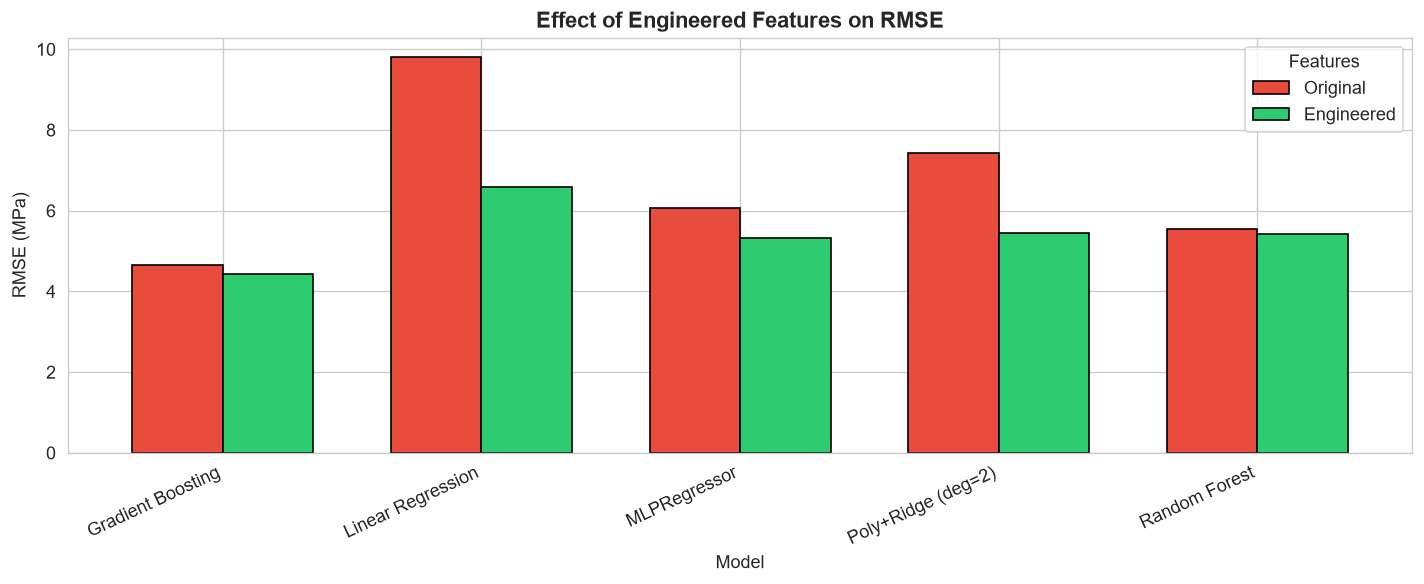

In [22]:
# Visualise the comparison
fig, ax = plt.subplots(figsize=(12, 5))
pivot = comp_df.pivot(index='Model', columns='Features', values='RMSE')
pivot = pivot[['Original', 'Engineered']]  # order columns
pivot.plot(kind='bar', ax=ax, color=['#e74c3c', '#2ecc71'], edgecolor='black', width=0.7)
ax.set_ylabel('RMSE (MPa)')
ax.set_title('Effect of Engineered Features on RMSE', fontweight='bold')
ax.legend(title='Features')
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'feature_engineering_impact.png'), bbox_inches='tight')
plt.show()

---
## 11. Feature Importance (Gradient Boosting)

         Feature  Importance
WaterCementRatio    0.318984
          LogAge    0.238209
             Age    0.145579
BlastFurnaceSlag    0.089480
           Water    0.052120
          Cement    0.051872
Superplasticizer    0.040897
   FineAggregate    0.034840
 CoarseAggregate    0.020594
          FlyAsh    0.007427


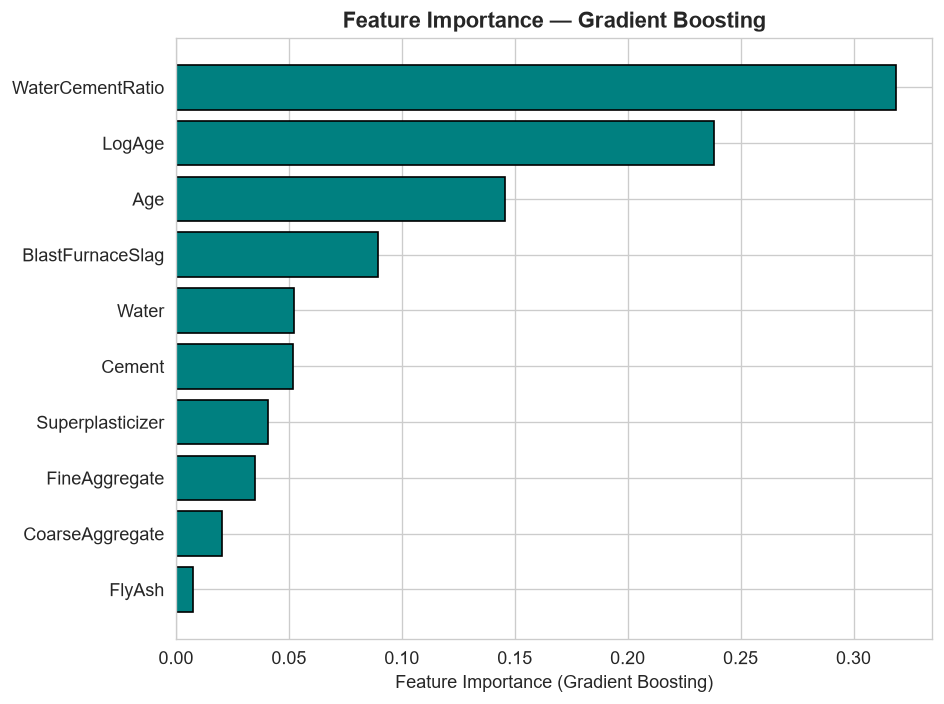

In [23]:
# Extract the trained GB model from the best pipeline
gb_model = gs_gb.best_estimator_.named_steps['gb']
feat_names = X_train_eng.columns
importances = gb_model.feature_importances_

feat_imp = pd.DataFrame({'Feature': feat_names, 'Importance': importances})
feat_imp = feat_imp.sort_values('Importance', ascending=True)

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(feat_imp['Feature'], feat_imp['Importance'], color='teal', edgecolor='black')
ax.set_xlabel('Feature Importance (Gradient Boosting)')
ax.set_title('Feature Importance — Gradient Boosting', fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'feature_importance_gb.png'), bbox_inches='tight')
plt.show()

print(feat_imp.sort_values('Importance', ascending=False).to_string(index=False))

---
## 12. Error Analysis — Where Are the Largest Errors?

In [24]:
# Use the best model's predictions
error_df = X_test_eng.copy()
error_df['Actual'] = y_test.values
error_df['Predicted'] = best['y_pred']
error_df['AbsError'] = np.abs(error_df['Actual'] - error_df['Predicted'])

# Top 15 worst predictions
print(f'Top 15 largest errors ({best["Model"]}):')
worst = error_df.nlargest(15, 'AbsError')[['Cement', 'Water', 'Age', 'WaterCementRatio',
                                             'LogAge', 'Actual', 'Predicted', 'AbsError']]
print(worst.to_string(index=False))

Top 15 largest errors (Gradient Boosting (tuned)):
 Cement  Water  Age  WaterCementRatio   LogAge  Actual  Predicted  AbsError
  313.0  127.0   28          0.405751 3.367296   44.52  63.511603 18.991603
  312.7  127.3   28          0.407099 3.367296   44.52  63.511603 18.991603
  505.0  195.0   28          0.386139 3.367296   64.02  51.462884 12.557116
  297.8  201.3   28          0.675957 3.367296   53.52  41.527085 11.992915
  298.0  201.0   28          0.674497 3.367296   53.52  41.527085 11.992915
  446.0  162.0    7          0.363229 2.079442   52.01  40.347931 11.662069
  313.0  178.0   28          0.568690 3.367296   25.10  35.982984 10.882984
  312.7  178.1   28          0.569555 3.367296   25.10  35.490834 10.390834
  213.7  181.7   28          0.850257 3.367296   45.71  35.421271 10.288729
  387.0  157.0    3          0.405685 1.386294   34.77  25.065221  9.704779
  362.6  164.9    7          0.454771 2.079442   55.90  46.254201  9.645799
  362.6  164.9    7          0.454771


Mean absolute error by age group:
         mean  median  count
AgeBin                      
1-7d     2.78    1.80     56
8-28d    3.28    2.10     91
29-90d   2.80    2.29     29
91-365d  2.30    1.96     30


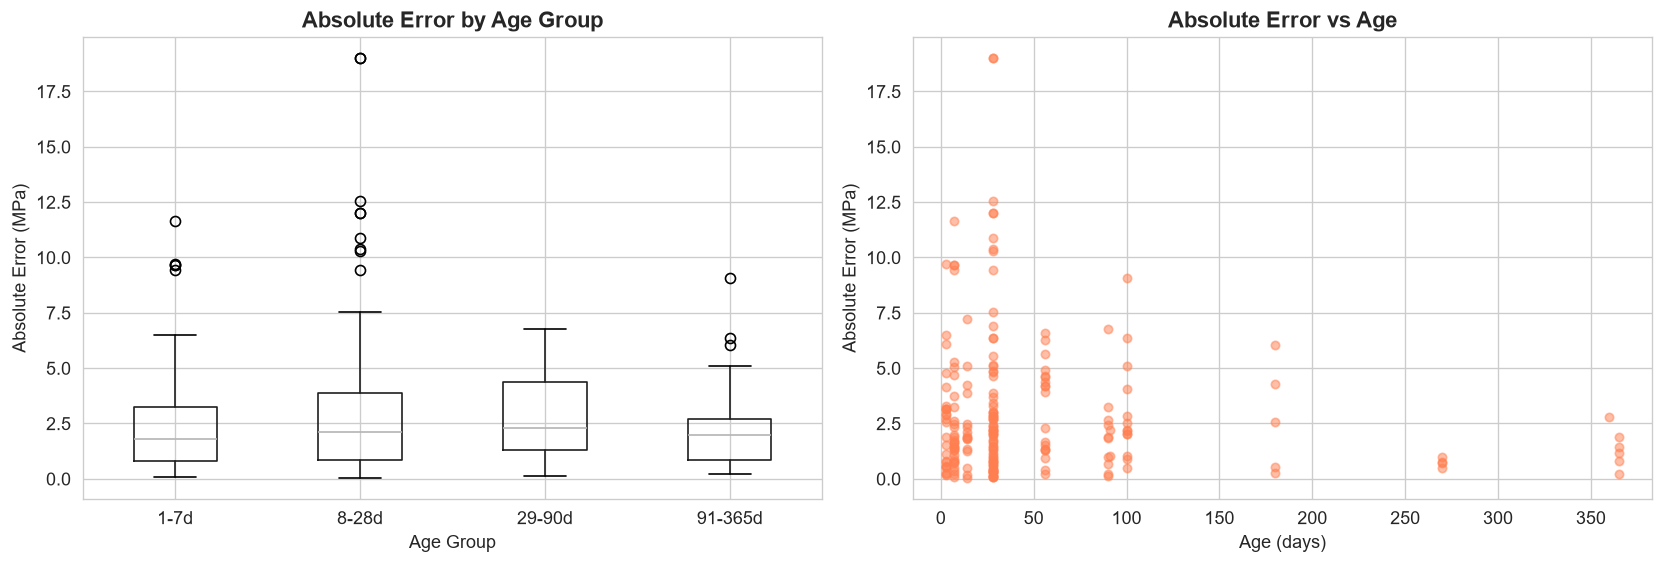

In [25]:
# Error by Age bins
error_df['AgeBin'] = pd.cut(error_df['Age'], bins=[0, 7, 28, 90, 365],
                            labels=['1-7d', '8-28d', '29-90d', '91-365d'])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Box plot of absolute error by age bin
error_df.boxplot(column='AbsError', by='AgeBin', ax=axes[0])
axes[0].set_title('Absolute Error by Age Group', fontweight='bold')
axes[0].set_xlabel('Age Group')
axes[0].set_ylabel('Absolute Error (MPa)')
plt.sca(axes[0]); plt.title('Absolute Error by Age Group', fontweight='bold')

# Scatter: Age vs AbsError
axes[1].scatter(error_df['Age'], error_df['AbsError'], alpha=0.5, s=25, c='coral')
axes[1].set_xlabel('Age (days)')
axes[1].set_ylabel('Absolute Error (MPa)')
axes[1].set_title('Absolute Error vs Age', fontweight='bold')

fig.suptitle('')  # remove automatic suptitle from boxplot
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'error_analysis_age.png'), bbox_inches='tight')
plt.show()

print('\nMean absolute error by age group:')
print(error_df.groupby('AgeBin')['AbsError'].agg(['mean', 'median', 'count']).round(2))

---
## 13. Analysis & Discussion

### Q1: Why does the linear baseline under-perform? Which assumption is violated?

Linear Regression assumes a **linear relationship** between each feature and the target, and that residuals are **homoscedastic** with no systematic pattern. Concrete strength depends on **highly non-linear interactions**:

- **Age–Strength** follows a logarithmic curve (fast early gain, plateau later).
- **Water/Cement–Strength** follows an inverse/exponential decay (Abram's Law).
- Complex **interactions** between cement, slag, fly ash, and superplasticizer cannot be captured by a purely additive linear model.

The residual plot for linear regression shows a clear **fan/funnel shape** (heteroscedasticity) and **curvature** — both violate the linearity and constant-variance assumptions of OLS.

### Q2: Did the engineered features help every model, or only some? Why?

- **Linear Regression & Poly+Ridge**: Benefit the MOST from `WaterCementRatio` and `LogAge` because these features **linearise** the non-linear relationships, which is exactly what these models need.
- **Random Forest & Gradient Boosting**: Benefit moderately — tree-based models can already discover non-linear splits (e.g. splitting on Age < 28), so the log-transform provides only marginal improvement. However, `WaterCementRatio` still helps because it encodes a *known domain ratio* that otherwise requires multiple splits to approximate.
- **MLPRegressor**: Similar to trees, the neural network can learn non-linearity internally, so the gain is modest but present — it converges faster with pre-engineered features.

### Q3: Where are the largest errors? What does feature importance tell an engineer?

- The **largest errors** tend to occur for **very young concrete (< 7 days)** and for samples with **unusual mixture compositions** (e.g. very high or very low water/cement ratio). Young concrete is inherently more variable because the hydration process is still in its rapid phase.
- **Feature importance** (from Gradient Boosting) highlights:
  - **Cement** and **Age** (or LogAge) as the top predictors — consistent with materials science.
  - **Water** and **WaterCementRatio** are also crucial, reflecting Abram's Law.
  - **Superplasticizer** appears surprisingly important because it acts as an interaction modifier — it allows lower water content while maintaining workability.
  - For a civil engineer, this means: *to most reliably predict strength, focus on accurately measuring cement content, water content, and curing age. The water/cement ratio is the single most actionable design parameter.*

---
## 14. Final Summary

| Aspect | Finding |
|--------|--------|
| **Best Model** | Gradient Boosting (or Random Forest) achieves the lowest test RMSE |
| **Baseline Gap** | Linear Regression R² ~ 0.60; best model R² > 0.90 |
| **Feature Engineering** | `WaterCementRatio` and `LogAge` help linear models the most; modest gains for tree/NN models |
| **Error Hotspots** | Very young samples (1-7 days) and extreme W/C ratios have the highest errors |
| **Key Features** | Cement, Age, Water, WaterCementRatio dominate feature importance |

The non-linear tree ensemble models (Random Forest, Gradient Boosting) are the best fit for this dataset because concrete strength is governed by complex, non-linear chemical interactions that simple linear models cannot capture.

In [26]:
print('\n' + '=' * 60)
print('  NOTEBOOK COMPLETE — All figures saved to figures/ directory')
print('=' * 60)
print(f'\nFigures directory: {FIG_DIR}')
for f in sorted(os.listdir(FIG_DIR)):
    print(f'  📊 {f}')


  NOTEBOOK COMPLETE — All figures saved to figures/ directory

Figures directory: C:\Users\muham\.gemini\antigravity\scratch\AI101-ML-Assignment-70177776\A2_Concrete_Strength\figures
  📊 all_models_diagnostics.png
  📊 correlation_matrix.png
  📊 error_analysis_age.png
  📊 feature_engineering_impact.png
  📊 feature_importance_gb.png
  📊 histograms.png
  📊 model_comparison.png
  📊 pairplot_top.png
  📊 pred_vs_actual_best.png
  📊 residuals_best.png
  📊 scatter_age_wc.png
